# **Heart Disease Classification Dataset**  
### O dataset utilizado é sobre doenças cardíacas e possui informações de 1.319 pacientes. Ele reúne dados como idade, gênero, frequência cardíaca, pressão arterial, nível de açúcar no sangue e alguns exames relacionados ao coração. O principal objetivo é analisar essas informações para identificar se o paciente teve ou não um ataque cardíaco. Dessa forma, os dados podem ajudar a entender quais características estão relacionadas à ocorrência de problemas cardíacos.

# 1 - Import das bibliotecas: bibliotecas que foram usadas para analisar os dados e criar o modelo.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

# imports usados nos gráficos novos
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.inspection import permutation_importance
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

# 2 - Import do dataset: carregamento do arquivo com os dados dos pacientes.

In [2]:
import os

# usa a cópia do dataset que está na pasta data/ do repositório; no Kaggle usa o dataset anexado ao notebook
if os.path.exists('../data/Heart_Attack.csv'):
    caminho = '../data/Heart_Attack.csv'
elif os.path.exists('data/Heart_Attack.csv'):
    caminho = 'data/Heart_Attack.csv'
else:
    caminho = '/kaggle/input/datasets/bharath011/heart-disease-classification-dataset/Heart Attack.csv'

data = pd.read_csv(caminho)
data.head()

,age,gender,impluse,pressurehight,pressurelow,glucose,kcm,troponin,class
0,64,1,66,160,83,160.0,1.80,0.012,negative
1,21,1,94,98,46,296.0,6.75,1.060,positive
2,55,1,64,160,77,270.0,1.99,0.003,negative
3,64,1,70,120,55,270.0,13.87,0.122,positive
4,55,1,64,112,65,300.0,1.08,0.003,negative


# 3 - Avaliação do banco de dados: conferencia das colunas e dos valores do dataset.

In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1319 entries, 0 to 1318
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   age            1319 non-null   int64  
 1   gender         1319 non-null   int64  
 2   impluse        1319 non-null   int64  
 3   pressurehight  1319 non-null   int64  
 4   pressurelow    1319 non-null   int64  
 5   glucose        1319 non-null   float64
 6   kcm            1319 non-null   float64
 7   troponin       1319 non-null   float64
 8   class          1319 non-null   str    
dtypes: float64(3), int64(5), str(1)
memory usage: 92.9 KB


In [4]:
data.describe()

,age,gender,impluse,pressurehight,pressurelow,glucose,kcm,troponin
count,1319.000000,1319.000000,1319.000000,1319.000000,1319.000000,1319.000000,1319.000000,1319.000000
mean,56.191812,0.659591,78.336619,127.170584,72.269143,146.634344,15.274306,0.360942
std,13.647315,0.474027,51.630270,26.122720,14.033924,74.923045,46.327083,1.154568
min,14.000000,0.000000,20.000000,42.000000,38.000000,35.000000,0.321000,0.001000
25%,47.000000,0.000000,64.000000,110.000000,62.000000,98.000000,1.655000,0.006000
50%,58.000000,1.000000,74.000000,124.000000,72.000000,116.000000,2.850000,0.014000
75%,65.000000,1.000000,85.000000,143.000000,81.000000,169.500000,5.805000,0.085500
max,103.000000,1.000000,1111.000000,223.000000,154.000000,541.000000,300.000000,10.300000


In [5]:
data.isnull().sum()

age              0
gender           0
impluse          0
pressurehight    0
pressurelow      0
glucose          0
kcm              0
troponin         0
class            0
dtype: int64

In [6]:
data.duplicated().sum()

np.int64(0)

# 3.1 - Casos positivos por faixa etaria: comparação do percentual de resultados positivos em cada faixa.

              total  positivos  percentual_positivo
faixa_etaria                                       
Até 29           53         21                39.62
30–39            99         38                38.38
40–49           231        112                48.48
50–59           316        202                63.92
60–69           384        255                66.41
70–79           197        151                76.65
80 ou mais       39         31                79.49


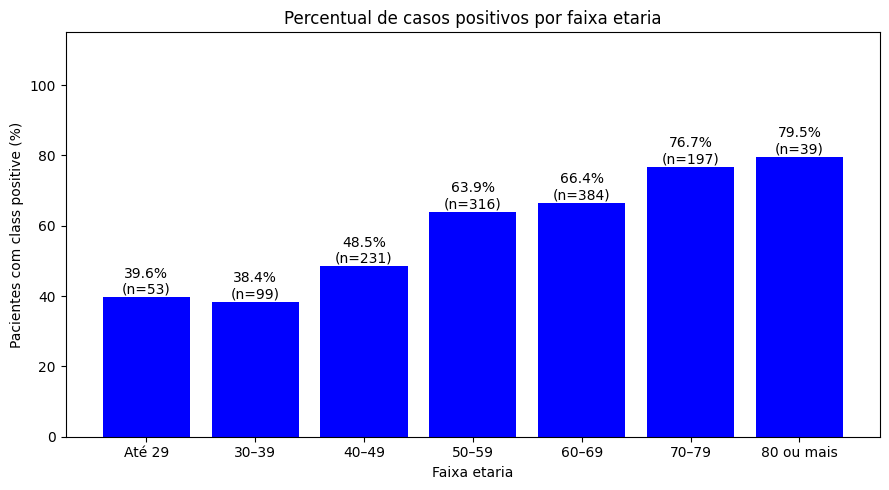

In [7]:
faixas = pd.cut(
    data['age'],
    bins=[0, 29, 39, 49, 59, 69, 79, float('inf')],
    labels=['Até 29', '30–39', '40–49', '50–59',
            '60–69', '70–79', '80 ou mais']
)

risco_por_idade = (
    data.assign(faixa_etaria=faixas)
        .groupby('faixa_etaria', observed=True)['class']
        .agg(
            total='count',
            positivos=lambda valores: valores.isin(['positive', 1]).sum()
        )
)

risco_por_idade['percentual_positivo'] = (
    risco_por_idade['positivos'] / risco_por_idade['total'] * 100
).round(2)

print(risco_por_idade)
plt.figure(figsize=(9, 5))

barras = plt.bar(
    risco_por_idade.index.astype(str),
    risco_por_idade['percentual_positivo'],
    color='blue'
)

for barra, total in zip(barras, risco_por_idade['total']):
    percentual = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        percentual + 1,
        f'{percentual:.1f}%\n(n={total})',
        ha='center'
    )

plt.ylim(0, 115)
plt.xlabel('Faixa etaria')
plt.ylabel('Pacientes com class positive (%)')
plt.title('Percentual de casos positivos por faixa etaria')
plt.tight_layout()
plt.show()

# 3.2 - Pressão alta por gênero: quantidade e percentual em cada grupo.

Contagem por genero:
gender
0    128
1    259
Name: pressao_alta, dtype: int64
Percentual por genero:
gender
0    28.51
1    29.77
Name: pressao_alta, dtype: float64


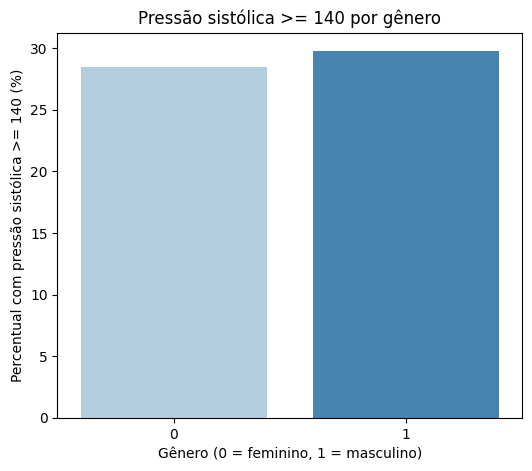

In [8]:
data['pressao_alta'] = data['pressurehight'] >= 140
casos_por_genero = data.groupby('gender')['pressao_alta'].sum()
total_por_genero = data.groupby('gender')['pressao_alta'].count()
percentual_por_genero = (casos_por_genero / total_por_genero * 100).round(2)
print('Contagem por genero:')
print(casos_por_genero)
print('Percentual por genero:')
print(percentual_por_genero)
plt.figure(figsize=(6, 5))
sns.barplot(x=percentual_por_genero.index,
 y=percentual_por_genero.values,
 hue=percentual_por_genero.index,
 palette='Blues', legend=False)
plt.xlabel('Gênero (0 = feminino, 1 = masculino)')
plt.ylabel('Percentual com pressão sistólica >= 140 (%)')
plt.title('Pressão sistólica >= 140 por gênero')
plt.show()


# 3.3 - Glicose de acordo com o resultado: comparação da glicose média entre os resultados positivo e negativo.

           quantidade   media  mediana
resultado                             
negative          509  149.76    117.0
positive          810  144.67    116.0


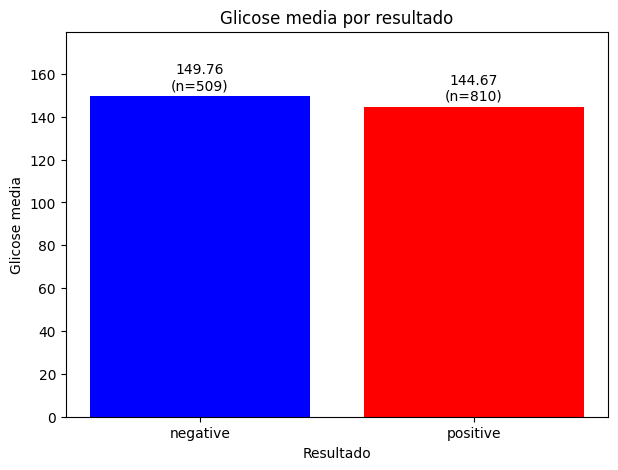

In [9]:
analise_glicose = data.assign(
    resultado=data['class'].replace({0: 'negative', 1: 'positive'})
)

resumo_glicose = analise_glicose.groupby('resultado')['glucose'].agg(
    quantidade='count',
    media='mean',
    mediana='median'
).round(2)

print(resumo_glicose)

plt.figure(figsize=(7, 5))

barras = plt.bar(
    resumo_glicose.index,
    resumo_glicose['media'],
    color=['blue', 'red']
)

for barra, (_, linha) in zip(barras, resumo_glicose.iterrows()):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 3,
        f"{linha['media']:.2f}\n(n={int(linha['quantidade'])})",
        ha='center'
    )

plt.ylim(0, resumo_glicose['media'].max() * 1.2)
plt.xlabel('Resultado')
plt.ylabel('Glicose media')
plt.title('Glicose media por resultado')
plt.show()

# 3.4 - Estilo dos gráficos: cores do pôster e nomes em português usados nos gráficos novos.

In [10]:
# cores do pôster (roxo = negativo, vermelho = positivo)
ROXO, ROXO_ESCURO, MAGENTA, VERMELHO, CINZA = '#6B2C91', '#2F2570', '#A02D8F', '#D62839', '#5C5873'

sns.set_theme(style='whitegrid', font_scale=0.95)
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})

# nomes em português para os gráficos ficarem fáceis de ler
nomes = {
    'age': 'Idade', 'gender': 'Gênero', 'impluse': 'Freq. cardíaca',
    'pressurehight': 'Pressão alta', 'pressurelow': 'Pressão baixa',
    'glucose': 'Glicose', 'kcm': 'CK-MB', 'troponin': 'Troponina',
    'class': 'Ataque cardíaco'
}

# 3.5 - Pacientes por resultado: proporção de casos positivos e negativos no dataset.

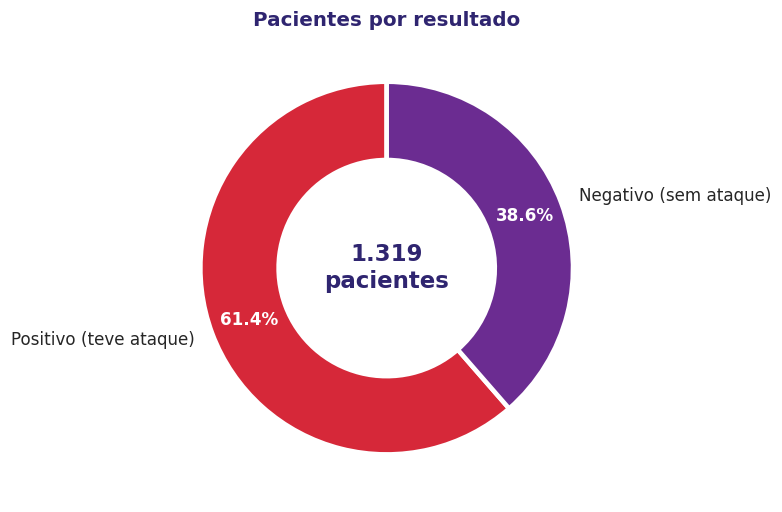

class
positive    810
negative    509
Name: count, dtype: int64


In [11]:
contagem = data['class'].value_counts()
rotulos = ['Positivo (teve ataque)' if c == 'positive' else 'Negativo (sem ataque)' for c in contagem.index]
cores = [VERMELHO if c == 'positive' else ROXO for c in contagem.index]

fig, ax = plt.subplots(figsize=(6, 5.5))
fatias, textos, percentuais = ax.pie(
    contagem.values, labels=rotulos, colors=cores, startangle=90,
    autopct=lambda p: f'{p:.1f}%', pctdistance=0.79,
    wedgeprops={'width': 0.42, 'edgecolor': 'white', 'linewidth': 3},
    textprops={'fontsize': 11}
)
for p in percentuais:
    p.set_color('white')
    p.set_fontweight('bold')
ax.text(0, 0, f'{contagem.sum():,}'.replace(',', '.') + '\npacientes', ha='center', va='center',
        fontsize=15, fontweight='bold', color=ROXO_ESCURO)
ax.set_title('Pacientes por resultado', fontweight='bold', color=ROXO_ESCURO, fontsize=13)
plt.show()

print(contagem)

# 3.6 - Exames do coração por resultado: comparação de troponina e CK-MB entre pacientes negativos e positivos.

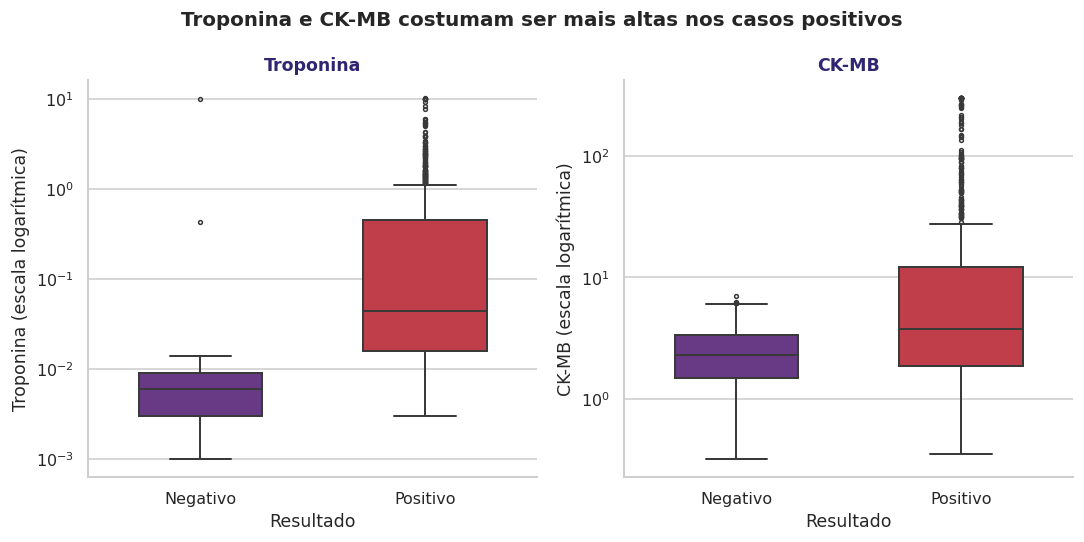

Mediana por resultado:
          troponin    kcm
class                    
negative     0.006  2.310
positive     0.044  3.775


In [12]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 5))
ordem = ['negative', 'positive']
paleta = {'negative': ROXO, 'positive': VERMELHO}

for eixo, coluna in zip(eixos, ['troponin', 'kcm']):
    sns.boxplot(data=data, x='class', y=coluna, order=ordem, hue='class',
                palette=paleta, legend=False, ax=eixo,
                width=0.55, fliersize=2.5, linewidth=1.3)
    eixo.set_yscale('log')
    eixo.set_xticks([0, 1])
    eixo.set_xticklabels(['Negativo', 'Positivo'])
    eixo.set_xlabel('Resultado')
    eixo.set_ylabel(f'{nomes[coluna]} (escala logarítmica)')
    eixo.set_title(nomes[coluna], fontweight='bold', color=ROXO_ESCURO)

plt.suptitle('Troponina e CK-MB costumam ser mais altas nos casos positivos',
             fontweight='bold', fontsize=13)
plt.tight_layout()
plt.show()

print('Mediana por resultado:')
print(data.groupby('class')[['troponin', 'kcm']].median().round(3))

# 4 - Dados faltantes: conferencia de valores vazios nas colunas.

In [13]:
data.isnull().sum()

age              0
gender           0
impluse          0
pressurehight    0
pressurelow      0
glucose          0
kcm              0
troponin         0
class            0
pressao_alta     0
dtype: int64

# 5 - Encoding: conversão dos resultados positivo e negativo para numeros.

In [14]:
encoder = LabelEncoder()
data['class'] = encoder.fit_transform(data['class'])
print('classes codificadas:')
for codigo, nome in enumerate(encoder.classes_):
 print(codigo, '=', nome)
print(data.head())


classes codificadas:
0 = negative
1 = positive
   age  gender  impluse  pressurehight  pressurelow  glucose    kcm  troponin  \
0   64       1       66            160           83    160.0   1.80     0.012   
1   21       1       94             98           46    296.0   6.75     1.060   
2   55       1       64            160           77    270.0   1.99     0.003   
3   64       1       70            120           55    270.0  13.87     0.122   
4   55       1       64            112           65    300.0   1.08     0.003   

   class  pressao_alta  
0      0          True  
1      1         False  
2      0          True  
3      1         False  
4      0         False  


# 5.1 - Correlação entre as variáveis: relação de cada variável com as outras e com o resultado (ataque cardíaco).

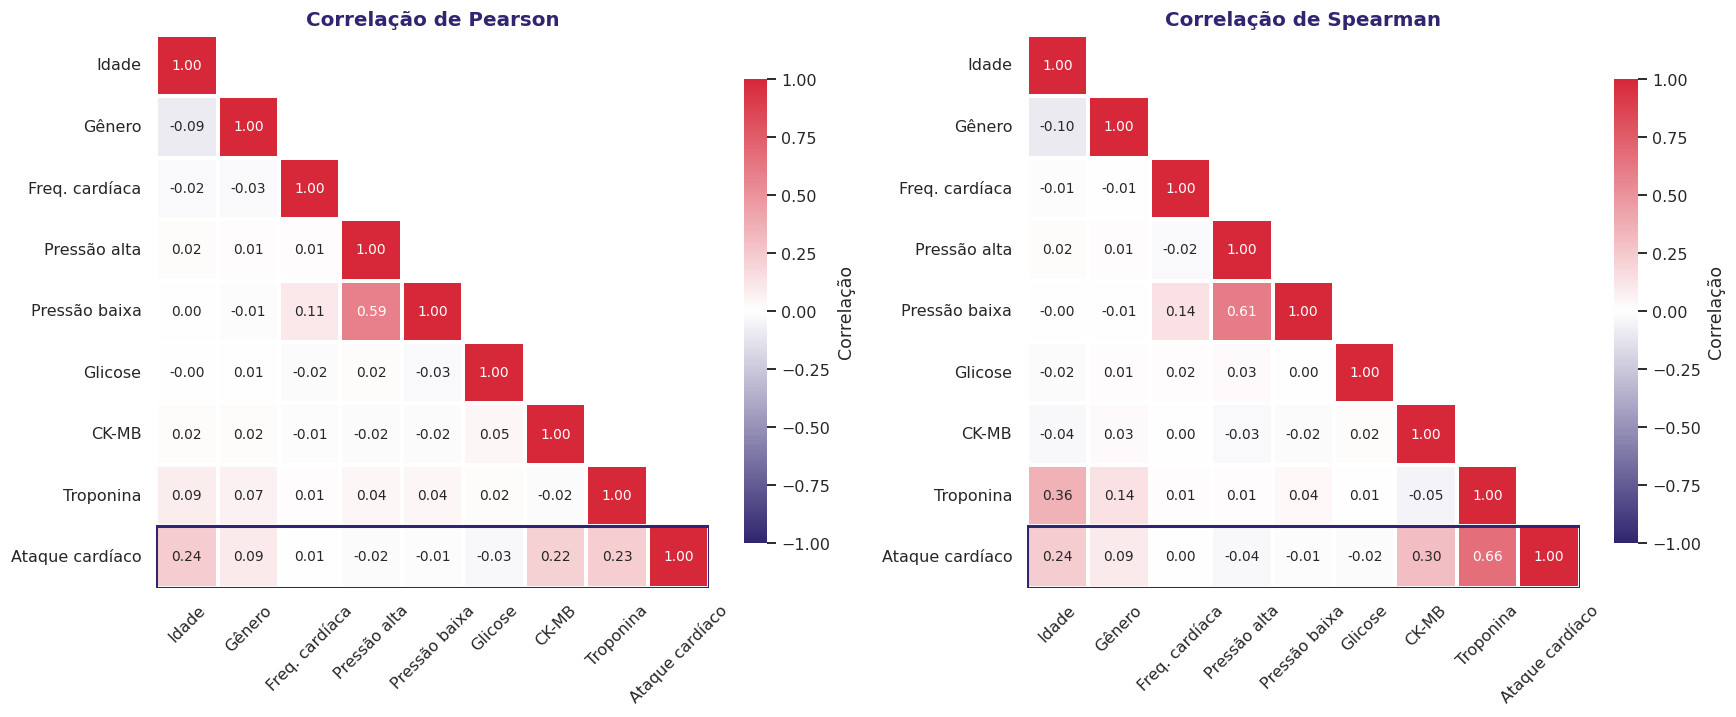

Correlação de cada variável com o resultado (Spearman):
Troponina         0.66
CK-MB             0.30
Idade             0.24
Gênero            0.09
Freq. cardíaca    0.00
Pressão baixa    -0.01
Glicose          -0.02
Pressão alta     -0.04
Name: class, dtype: float64


In [15]:
colunas = ['age', 'gender', 'impluse', 'pressurehight', 'pressurelow',
           'glucose', 'kcm', 'troponin', 'class']

corr_pearson = data[colunas].corr(method='pearson')
corr_spearman = data[colunas].corr(method='spearman')

cmap_corr = LinearSegmentedColormap.from_list('roxo_vermelho', [ROXO_ESCURO, 'white', VERMELHO])

fig, eixos = plt.subplots(1, 2, figsize=(16, 7))
for eixo, corr, titulo in zip(eixos, [corr_pearson, corr_spearman],
                              ['Correlação de Pearson', 'Correlação de Spearman']):
    mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)   # mostra só metade, sem repetir
    sns.heatmap(corr.rename(index=nomes, columns=nomes), mask=mascara, annot=True, fmt='.2f',
                cmap=cmap_corr, vmin=-1, vmax=1, center=0, square=True,
                linewidths=1.5, linecolor='white', annot_kws={'fontsize': 9},
                cbar_kws={'shrink': 0.7, 'label': 'Correlação'}, ax=eixo)
    eixo.grid(False)
    eixo.add_patch(plt.Rectangle((0, len(colunas) - 1), len(colunas), 1, fill=False,
                                 edgecolor=ROXO_ESCURO, linewidth=2))   # destaca a linha do resultado
    eixo.set_title(titulo, fontweight='bold', color=ROXO_ESCURO, fontsize=13)
    eixo.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

print('Correlação de cada variável com o resultado (Spearman):')
print(corr_spearman['class'].drop('class').rename(index=nomes).sort_values(ascending=False).round(2))

**Como ler:** quanto mais perto de 1 (vermelho), mais as duas variáveis sobem juntas; perto de 0 (branco), não têm relação; perto de -1 (roxo), uma sobe quando a outra desce. A última linha de cada gráfico mostra a relação de cada variável com o ataque cardíaco.

A correlação de **Spearman** é a mais indicada aqui porque troponina e CK-MB têm poucos valores muito altos, e isso faz a correlação de Pearson subestimar a relação delas com o resultado.

# 5.2 - Distribuição das variáveis por resultado: formato dos valores em pacientes negativos e positivos.

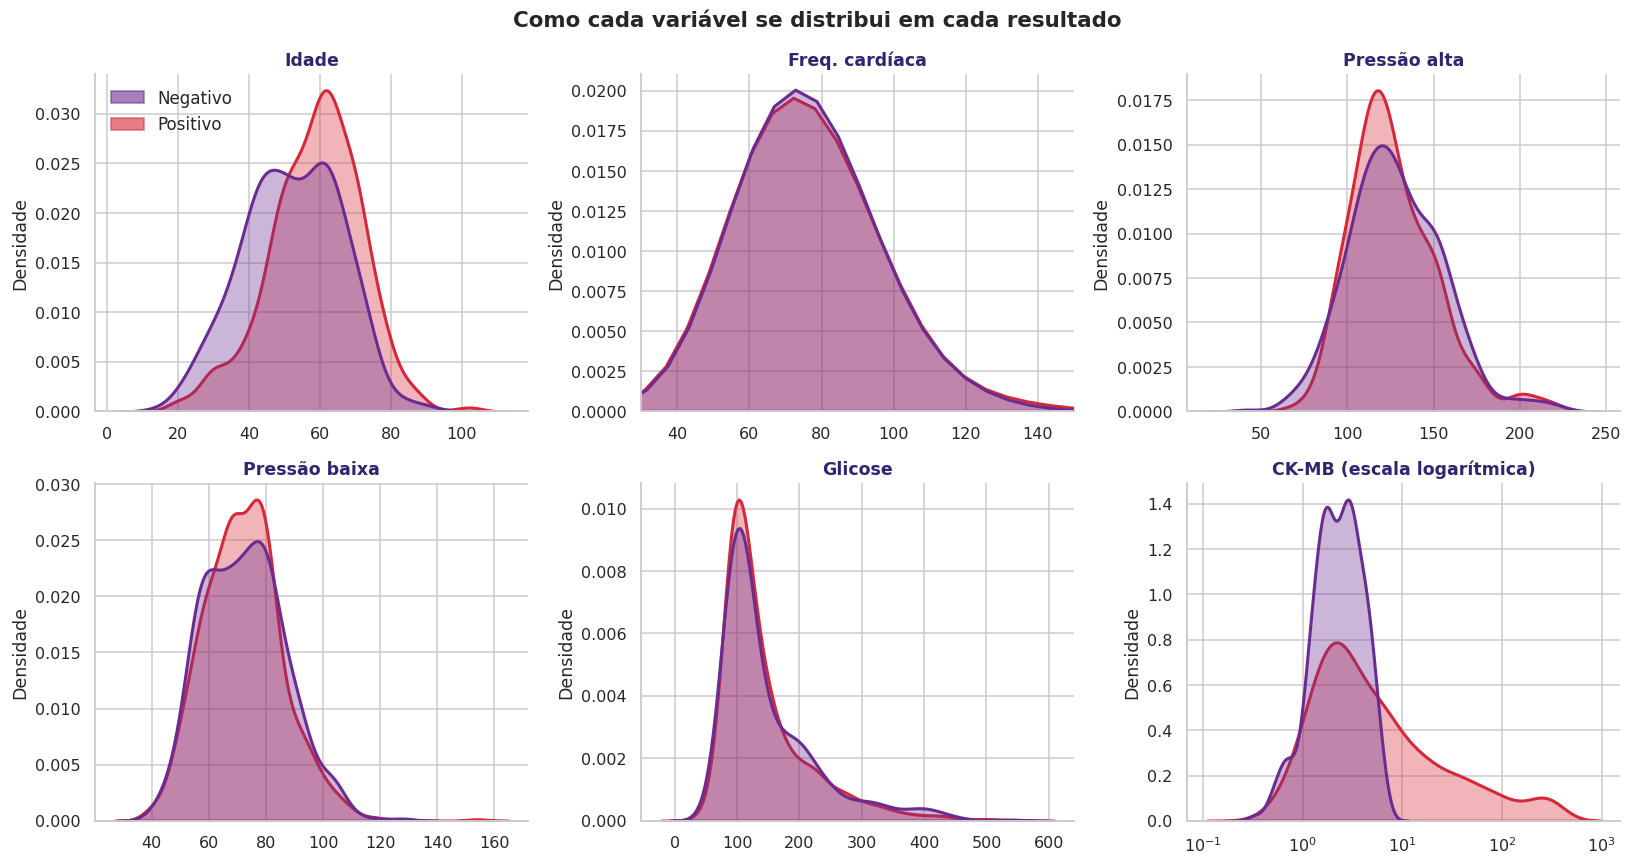

In [16]:
variaveis = ['age', 'impluse', 'pressurehight', 'pressurelow', 'glucose', 'kcm']
paleta_kde = {0: ROXO, 1: VERMELHO}

fig, eixos = plt.subplots(2, 3, figsize=(15, 8))
for eixo, coluna in zip(eixos.ravel(), variaveis):
    sns.kdeplot(data=data, x=coluna, hue='class', palette=paleta_kde, fill=True,
                alpha=0.35, linewidth=2, common_norm=False, legend=False,
                log_scale=(coluna == 'kcm'), ax=eixo)
    titulo = nomes[coluna] + (' (escala logarítmica)' if coluna == 'kcm' else '')
    eixo.set_title(titulo, fontweight='bold', color=ROXO_ESCURO)
    eixo.set_xlabel('')
    eixo.set_ylabel('Densidade')
    if coluna == 'impluse':
        eixo.set_xlim(30, 150)   # alguns valores absurdos (máx. 1111) ficam de fora do gráfico

eixos[0, 0].legend(handles=[Patch(color=ROXO, alpha=0.6, label='Negativo'),
                            Patch(color=VERMELHO, alpha=0.6, label='Positivo')],
                   loc='upper left', frameon=False, fontsize=11)
plt.suptitle('Como cada variável se distribui em cada resultado', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

**Observação sobre os dados:** a frequência cardíaca (`impluse`) tem 3 valores acima de 150 (o máximo é 1111), que não são plausíveis para um paciente. Eles não foram removidos para manter o resultado do modelo igual ao original; neste gráfico o eixo foi limitado entre 30 e 150.

# 6 - Divisão dos dados de teste e treino: separação dos dados para treinar e testar o modelo.

In [17]:
X = data.drop(['class', 'pressao_alta'], axis=1)
y = data['class'].values
X_train, X_test, y_train, y_test = train_test_split(
 X, y, test_size=0.2, random_state=42, stratify=y
)
print('treino:', X_train.shape)
print('teste:', X_test.shape)

treino: (1055, 8)
teste: (264, 8)


# 7 - GridSearchCV: teste de diferentes configurações para o SVM.

In [18]:
model_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', SVC(kernel='rbf', C=1, gamma='scale'))
])

model_pipeline.fit(X_train, y_train)
y_pred_inicial = model_pipeline.predict(X_test)

print(f'Acurácia antes da otimização: {accuracy_score(y_test, y_pred_inicial):.2f}')

param_grid = [
    {
        'classifier__kernel': ['linear'],
        'classifier__C': [0.1, 1, 10]
    },
    {
        'classifier__kernel': ['rbf'],
        'classifier__C': [0.1, 1, 10],
        'classifier__gamma': ['scale', 0.01, 0.1]
    }
]

grid_search = GridSearchCV(
    model_pipeline,
    param_grid,
    cv=5,
    scoring='accuracy',
    verbose=0,
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
best_score = grid_search.best_score_

print('Melhores parametros:', best_params)
print(f'Acurácia media na validação cruzada: {best_score:.2f}')

best_model = grid_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)
accuracy_tuned = accuracy_score(y_test, y_pred_tuned)

print(f'Acurácia apss a otimização: {accuracy_tuned:.2f}')

Acurácia antes da otimização: 0.75


Melhores parametros: {'classifier__C': 10, 'classifier__kernel': 'linear'}
Acurácia media na validação cruzada: 0.81
Acurácia apss a otimização: 0.84


# 8 - Treino do modelo com teste: conferência da acurácia e dos erros do modelo escolhido.

In [19]:
y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])
classification_rep = classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=['negative', 'positive']
)

print(f'Acurácia no teste: {accuracy:.2f}')
print('Matriz de confusão:')
print(conf_matrix)
print(classification_rep)

results_df = pd.DataFrame({
    'Atual': y_test,
    'Previsto': y_pred
}, index=X_test.index)

results_df = results_df.replace({0: 'negative', 1: 'positive'})

print('Alguns resultados reais e previstos:')
print(results_df.head())

Acurácia no teste: 0.84
Matriz de confusão:
[[ 86  16]
 [ 27 135]]
              precision    recall  f1-score   support

    negative       0.76      0.84      0.80       102
    positive       0.89      0.83      0.86       162

    accuracy                           0.84       264
   macro avg       0.83      0.84      0.83       264
weighted avg       0.84      0.84      0.84       264

Alguns resultados reais e previstos:
         Atual  Previsto
1295  positive  positive
139   negative  negative
160   positive  positive
1184  negative  negative
474   negative  negative


# 8.1 - Exemplos de previsão: comparação de algumas previsões com os resultados reais.

In [20]:
print('Exemplos de previsão:')

for i in range(3):
    sample_data = X_test.iloc[[i]]
    prediction = best_model.predict(sample_data)[0]

    previsto = 'positive' if prediction == 1 else 'negative'
    real = 'positive' if y_test[i] == 1 else 'negative'

    print(f'Exemplo {i + 1}: resultado real = {real}, previsão = {previsto}')

Exemplos de previsão:
Exemplo 1: resultado real = positive, previsão = positive
Exemplo 2: resultado real = negative, previsão = negative
Exemplo 3: resultado real = positive, previsão = positive


# 9 - Matriz de confusão: visualização dos acertos e erros para cada resultado.

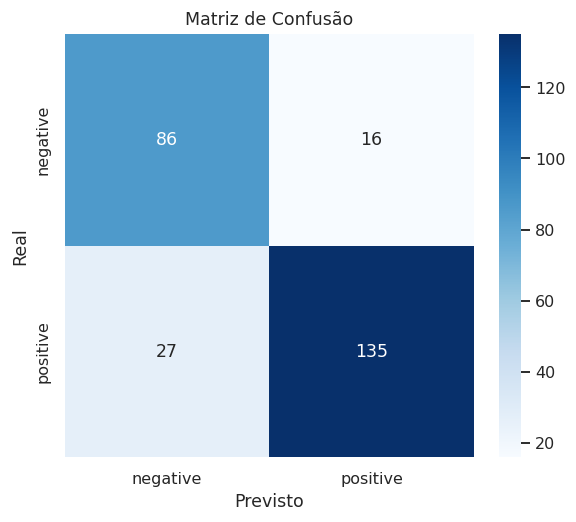

In [21]:
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
 xticklabels=encoder.classes_,
 yticklabels=encoder.classes_)
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.title('Matriz de Confusão')
plt.show()

# 9.1 - Matriz de confusão detalhada: quantidade e percentual de acertos e erros em cada resultado.

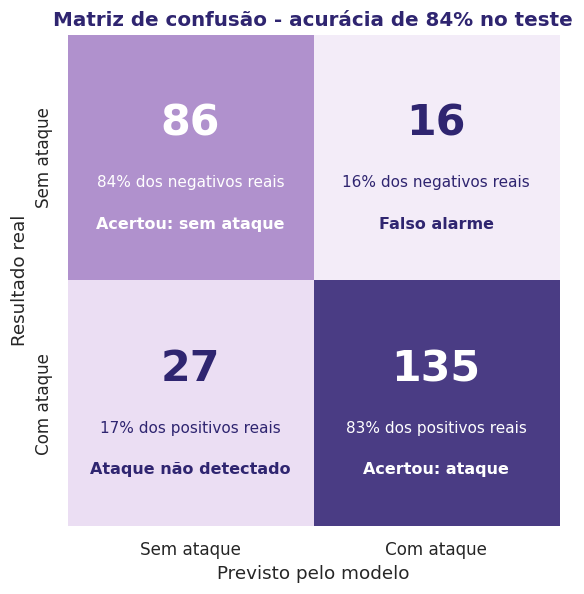

In [22]:
percentual = conf_matrix / conf_matrix.sum(axis=1, keepdims=True) * 100
legendas = [['Acertou: sem ataque', 'Falso alarme'],
            ['Ataque não detectado', 'Acertou: ataque']]
cmap_cm = LinearSegmentedColormap.from_list('roxo', ['#FFFFFF', '#C9A6E0', ROXO_ESCURO])

fig, ax = plt.subplots(figsize=(7, 5.8))
ax.imshow(conf_matrix, cmap=cmap_cm, vmin=0, vmax=conf_matrix.max() * 1.1)
ax.grid(False)

for i in range(2):
    for j in range(2):
        cor = 'white' if conf_matrix[i, j] > conf_matrix.max() * 0.5 else ROXO_ESCURO
        grupo = 'negativos' if i == 0 else 'positivos'
        ax.text(j, i - 0.14, f'{conf_matrix[i, j]}', ha='center', va='center',
                fontsize=28, fontweight='bold', color=cor)
        ax.text(j, i + 0.10, f'{percentual[i, j]:.0f}% dos {grupo} reais', ha='center',
                va='center', fontsize=10, color=cor)
        ax.text(j, i + 0.27, legendas[i][j], ha='center', va='center',
                fontsize=10.5, fontweight='bold', color=cor)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])
ax.set_xticklabels(['Sem ataque', 'Com ataque'], fontsize=11)
ax.set_yticklabels(['Sem ataque', 'Com ataque'], fontsize=11, rotation=90, va='center')
ax.set_xlabel('Previsto pelo modelo', fontsize=12)
ax.set_ylabel('Resultado real', fontsize=12)
ax.set_title(f'Matriz de confusão - acurácia de {accuracy:.0%} no teste',
             fontweight='bold', color=ROXO_ESCURO, fontsize=13)
for lado in ax.spines.values():
    lado.set_visible(False)
plt.show()

# 9.2 - Curva ROC: capacidade do modelo de separar pacientes positivos e negativos.

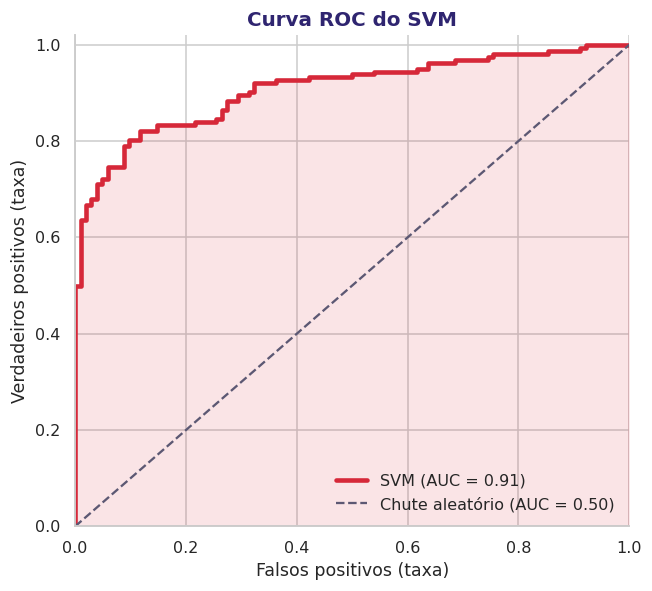

AUC: 0.91


In [23]:
pontuacao = best_model.decision_function(X_test)
fpr, tpr, _ = roc_curve(y_test, pontuacao)
auc_valor = roc_auc_score(y_test, pontuacao)

fig, ax = plt.subplots(figsize=(6.5, 5.8))
ax.plot(fpr, tpr, color=VERMELHO, linewidth=3, label=f'SVM (AUC = {auc_valor:.2f})')
ax.fill_between(fpr, tpr, alpha=0.12, color=VERMELHO)
ax.plot([0, 1], [0, 1], '--', color=CINZA, linewidth=1.5, label='Chute aleatório (AUC = 0.50)')
ax.set_xlabel('Falsos positivos (taxa)')
ax.set_ylabel('Verdadeiros positivos (taxa)')
ax.set_title('Curva ROC do SVM', fontweight='bold', color=ROXO_ESCURO, fontsize=13)
ax.legend(loc='lower right', frameon=False)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
plt.show()

print(f'AUC: {auc_valor:.2f}')

# 9.3 - Importância das variáveis: quanto a acurácia cai quando cada variável é embaralhada (permutação).

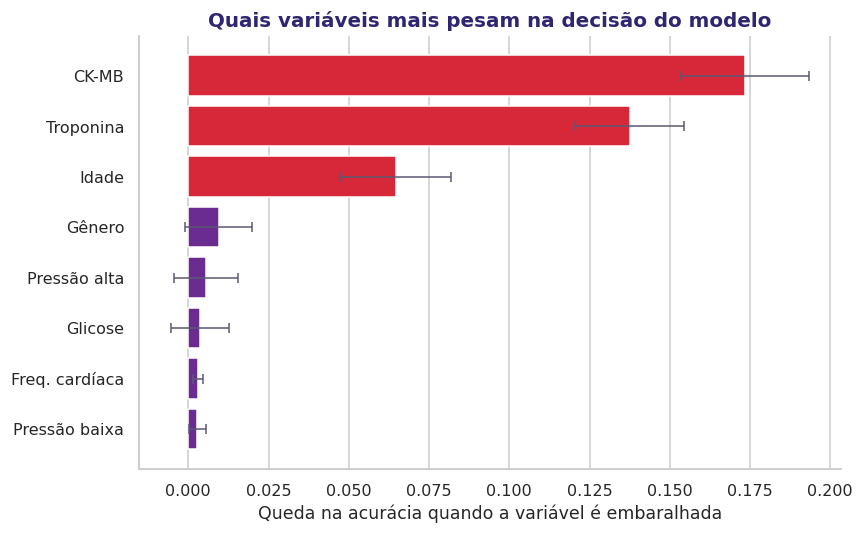

      variavel  media  desvio
         CK-MB  0.173   0.020
     Troponina  0.138   0.017
         Idade  0.065   0.017
        Gênero  0.009   0.010
  Pressão alta  0.005   0.010
       Glicose  0.004   0.009
Freq. cardíaca  0.003   0.002
 Pressão baixa  0.003   0.003


In [24]:
resultado_perm = permutation_importance(
    best_model, X_test, y_test, n_repeats=20, random_state=42,
    scoring='accuracy', n_jobs=-1
)

importancia = pd.DataFrame({
    'variavel': [nomes[c] for c in X_test.columns],
    'media': resultado_perm.importances_mean,
    'desvio': resultado_perm.importances_std
}).sort_values('media')

cores = [VERMELHO if m >= 0.05 else ROXO for m in importancia['media']]

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importancia['variavel'], importancia['media'], xerr=importancia['desvio'],
        color=cores, capsize=3, error_kw={'ecolor': CINZA, 'linewidth': 1})
ax.set_xlabel('Queda na acurácia quando a variável é embaralhada')
ax.set_title('Quais variáveis mais pesam na decisão do modelo',
             fontweight='bold', color=ROXO_ESCURO, fontsize=13)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.show()

print(importancia.sort_values('media', ascending=False).round(3).to_string(index=False))

# 9.4 - Acurácia antes e depois da otimização: comparação do modelo inicial com o modelo ajustado pelo GridSearchCV.

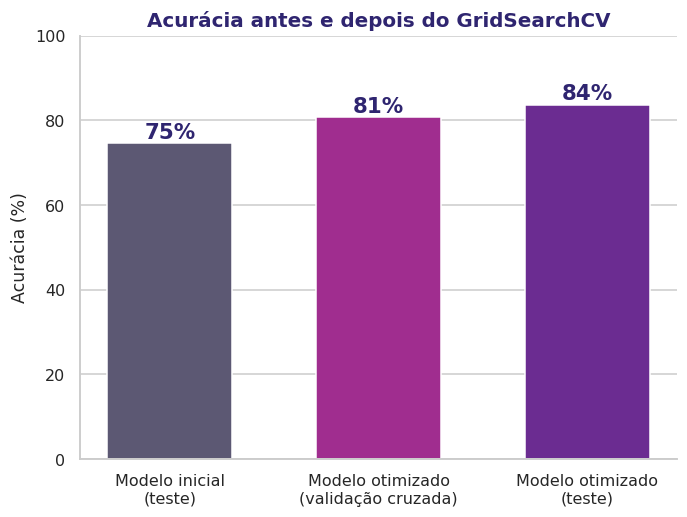

In [25]:
valores = [accuracy_score(y_test, y_pred_inicial), best_score, accuracy_tuned]
nomes_barras = ['Modelo inicial\n(teste)', 'Modelo otimizado\n(validação cruzada)', 'Modelo otimizado\n(teste)']
cores_barras = [CINZA, MAGENTA, ROXO]

fig, ax = plt.subplots(figsize=(7, 5))
barras = ax.bar(nomes_barras, [v * 100 for v in valores], color=cores_barras, width=0.6)
for barra, v in zip(barras, valores):
    ax.text(barra.get_x() + barra.get_width() / 2, v * 100 + 1.2, f'{v:.0%}',
            ha='center', fontsize=14, fontweight='bold', color=ROXO_ESCURO)
ax.set_ylim(0, 100)
ax.set_ylabel('Acurácia (%)')
ax.set_title('Acurácia antes e depois do GridSearchCV', fontweight='bold', color=ROXO_ESCURO, fontsize=13)
ax.grid(axis='x', visible=False)
plt.show()

**O que os gráficos novos mostram (em linguagem simples):**

- **Correlação:** troponina (0,67 em Spearman), CK-MB (0,30) e idade (0,24) são as variáveis mais ligadas ao ataque cardíaco; pressão, glicose e frequência cardíaca ficam perto de zero.
- **Matriz de confusão:** de 264 pacientes de teste, o modelo acertou 221. Foram 16 falsos alarmes e 27 ataques não detectados.
- **Curva ROC:** a área sob a curva (AUC) foi de 0,91, ou seja, o modelo separa bem os dois grupos.
- **Importância das variáveis:** CK-MB e troponina são as que mais pesam na decisão do modelo, e a idade vem em terceiro. As demais quase não mudam o resultado.

# Conclusão


### O estudo analisou dados de 1.319 pacientes para prever ataques cardíacos com base em variáveis clínicas como idade, pressão arterial, glicose e marcadores cardíacos. A análise mostrou que o risco de ataque cardíaco aumenta claramente com a idade, enquanto pressão alta e glicose não variaram muito entre os grupos positivo e negativo.Para a classificação, foi usado um modelo SVM, otimizado com GridSearchCV, que atingiu 84% de acurácia no teste (partindo de 75% no modelo inicial), com bom equilíbrio entre precisão e revocação para as duas classes.Conclui-se que o modelo teve desempenho satisfatório e que a idade é um fator determinante para o risco cardíaco. Como próximos passos, sugere-se testar outros algoritmos e ampliar a base de dados para melhorar ainda mais a precisão das previsões.
